# PCA — ChurnData 주성분 분석

카페: [PCA](https://cafe.naver.com/f-e/cafes/31780422/articles/634)  
세션 노트: [session30.md](../session30.md)

> **쉬운 말**  
> 고객 이탈 표의 칸이 많을 때, **정보가 많이 담긴 새 축**만 남깁니다.  
> 먼저 로지스틱으로 맞춘 뒤, **PCA**로 칸을 줄여 다시 학습·그려 봅니다.  
> 데이터는 ../data/ChurnData.csv로 읽습니다.


In [2]:
#PCA : 주성분분석(데이터의 핵심 특징만 남기고 차원은 줄인다)
#분산이 가장 큰 방향 찾는다(데이터가 가장 넓게 퍼져있는 방향) -> 정보가 많다
#1주성분(PC1)/ 2주성분(PC2) : PC1과 직교하는 방향

In [3]:
import pandas as pd #데이터 처리/분석
import matplotlib.pyplot as plt #데이터 시각화
import numpy as np #수치계산/배열/연산
from sklearn.preprocessing import StandardScaler  #정규화(표준화) 스케일링
from sklearn.model_selection import train_test_split #학습용과 테스트용 나누는 함수
from sklearn.linear_model import LogisticRegression #로지스틱 회귀모델 
from sklearn.metrics import accuracy_score #예측값, 실제값 비교해서 정확도 계산하는 함수

In [4]:
df=pd.read_csv('../data/ChurnData.csv')
df

,tenure,age,address,income,ed,employ,equip,callcard,wireless,longmon,tollmon,equipmon,cardmon,wiremon,longten,tollten,cardten,voice,pager,internet,callwait,confer,ebill,loglong,logtoll,lninc,custcat,churn
0,11.0,33.0,7.0,136.0,5.0,5.0,0.0,1.0,1.0,4.40,20.75,0.00,15.25,35.7,42.00,211.45,125.0,1.0,1.0,0.0,1.0,1.0,0.0,1.482,3.033,4.913,4.0,1.0
1,33.0,33.0,12.0,33.0,2.0,0.0,0.0,0.0,0.0,9.45,0.00,0.00,0.00,0.0,288.80,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.246,3.240,3.497,1.0,1.0
2,23.0,30.0,9.0,30.0,1.0,2.0,0.0,0.0,0.0,6.30,0.00,0.00,0.00,0.0,157.05,0.00,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.841,3.240,3.401,3.0,0.0
3,38.0,35.0,5.0,76.0,2.0,10.0,1.0,1.0,1.0,6.05,45.00,50.10,23.25,64.9,239.55,1873.05,880.0,1.0,1.0,1.0,1.0,1.0,1.0,1.800,3.807,4.331,4.0,0.0
4,7.0,35.0,14.0,80.0,2.0,15.0,0.0,1.0,0.0,7.10,22.00,0.00,23.75,0.0,47.45,166.10,145.0,1.0,0.0,0.0,1.0,1.0,0.0,1.960,3.091,4.382,3.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
195,55.0,44.0,24.0,83.0,1.0,23.0,0.0,1.0,0.0,17.35,24.50,0.00,14.25,0.0,973.10,1343.50,720.0,0.0,0.0,0.0,0.0,1.0,0.0,2.854,3.199,4.419,3.0,0.0
196,34.0,23.0,3.0,24.0,1.0,7.0,0.0,1.0,0.0,6.00,28.00,0.00,12.75,0.0,203.25,959.40,435.0,0.0,0.0,0.0,1.0,1.0,0.0,1.792,3.332,3.178,3.0,0.0
197,6.0,32.0,10.0,47.0,1.0,10.0,0.0,1.0,0.0,3.85,23.75,0.00,12.50,0.0,29.90,128.45,80.0,0.0,0.0,0.0,1.0,1.0,0.0,1.348,3.168,3.850,3.0,0.0
198,24.0,30.0,0.0,25.0,4.0,5.0,0.0,1.0,1.0,8.70,47.75,0.00,32.75,64.0,186.60,1152.90,780.0,1.0,1.0,1.0,1.0,1.0,1.0,2.163,3.866,3.219,4.0,1.0


In [8]:
#피처(입력) /라벨(정답) 나누기
#피처: 모델이 학습할 데이터
#라벨: 모델이 예측할 데이터(컬럼)
#churn 제외
columns=df.columns[:-1] #처음부터 끝에서 하나 전까지

#마지막 컬럼 제외하고 피처줌(모델이 학습할 입력 데이터)
features=df.loc[:, columns]

label=df['churn']

In [9]:
#20프로만 테스트용
X_train, X_test, y_train, y_test=train_test_split(features, label, test_size=0.2, random_state=1)

In [11]:
#표준화 시키기
sc=StandardScaler()
X_train=sc.fit_transform(X_train)
X_test=sc.transform(X_test)

In [12]:
#shape찍어보기 - 문제데이터: 열있음
X_train.shape, y_train.shape, X_test.shape, y_test.shape

((160, 27), (160,), (40, 27), (40,))

In [16]:
lr=LogisticRegression(solver='lbfgs', random_state=1)
#학습데이터의 문제와 정답을 주고 학습시킨다.
#y=wx+b
lr.fit(X_train, y_train);

In [17]:
#예측, 정확도
#테스트용 문제를 주며 정답을 예측한다
y_pred=lr.predict(X_test)
#실제값과 모델이 예측한 값을 비교해 정확도 출력
accuracy_score(y_test, y_pred)

0.825

In [45]:
#PCA적용
from sklearn.decomposition import PCA
#2차원
pca=PCA()

In [46]:
#어느방향으로 가장 넓게 퍼져있는지 찾아냄(주성분축) -> 찾아낸 축 기준으로 학습 데이터를 2차원으로 변환
#fit: 분산이 가장 큰 방향 찾음(주성분축) / transform: 찾아낸 축 기준으로 학습 데이터를 27차원 -> 2차원으로 변환
X_train_pca=pca.fit_transform(X_train)
#테스트 데이터는 새로운 축 찾는데 관여하지 않음(학습데이터에서 찾았던 축 그대로 사용)
X_test_pca=pca.transform(X_test)

In [47]:
X_train_pca.shape, X_test_pca.shape  #27개 컬럼을 섞어서 2개 축을 새로 만듬

((160, 27), (40, 27))

In [48]:
#주성분 크기
#원본데이터 27차원 / pca로 2차원으로 축 2개 만들어 축소시킴

#PC1=w1*tenure + w2*age + .......w27*custcat

print(pca.components_[0]) #pc1 -> 가장 많은 분산을 설명하는 방향의 벡터값
print(pca.components_[1]) #pc2 -> pc1에 직교하면서 두번째로 많은 분산을 설명하는 방향의 벡터값

#주성분에 크게 기여하는 컬럼: 벡터값이 큰 값 (절대값)
#        거의 기여하지 않는 컬럼 : 0에 가까우누 값

[0.22868251 0.14591258 0.10393308 0.05228089 0.03940592 0.16455981
 0.04773625 0.22721116 0.21080861 0.20312999 0.26000934 0.11785771
 0.25597858 0.25325173 0.20559347 0.28029559 0.2426773  0.20781866
 0.23437339 0.02717868 0.21531435 0.20054001 0.03148224 0.21684582
 0.18617202 0.12441312 0.26489625]
[ 0.24256672  0.20454345  0.23485898  0.03972271 -0.1679365   0.20451427
 -0.20965314  0.08615314 -0.25912194  0.27180971 -0.14444607 -0.23506371
  0.13265303 -0.23935328  0.27511454 -0.05795038  0.20371649 -0.21787441
 -0.19855337 -0.22867159 -0.13434126 -0.12062796 -0.18349733  0.25681055
 -0.04266005  0.06949854 -0.17478113]


In [49]:
#(n_components 설정값, n_features 원복특성개수)
pca.components_.shape

(27, 27)

In [50]:
#주성분이 전체분산의 몇% 설명하냐, 두 주성분 합쳤을때 %값
print(pca.explained_variance_ratio_, sum(pca.explained_variance_ratio_))

[2.61110081e-01 2.22142357e-01 1.18088151e-01 8.31968325e-02
 4.24554083e-02 3.77004306e-02 2.93983931e-02 2.64469353e-02
 2.14220573e-02 2.03353220e-02 1.90499055e-02 1.74217721e-02
 1.62448098e-02 1.51309259e-02 1.24679758e-02 1.15624253e-02
 9.42659340e-03 8.81126313e-03 6.67682335e-03 6.04799918e-03
 4.75746540e-03 3.65130325e-03 3.08793895e-03 1.64491474e-03
 8.72644421e-04 7.61917981e-04 8.73543104e-05] 1.0


In [62]:
c=np.cumsum(pca.explained_variance_ratio_)
#정보의 90%유지하려면 주성분이 몇개 필요한지 알아내려고
print(np.argmax(c>=0.90)+1)

13


In [76]:
pca=PCA(n_components=13)
X_train_pca=pca.fit_transform(X_train)
#테스트 데이터는 새로운 축 찾는데 관여하지 않음(학습데이터에서 찾았던 축 그대로 사용)
X_test_pca=pca.transform(X_test)
X_train_pca

array([[-1.88271112,  0.88827871, -0.70044795, ...,  0.74536622,
         0.39532564, -0.80930229],
       [-3.89310389, -0.25301692, -1.03230062, ..., -0.1069651 ,
        -0.70670782,  0.27690867],
       [ 0.33925232,  1.50712204,  1.58237982, ..., -1.49510413,
         0.05875169,  1.2276566 ],
       ...,
       [ 0.24012978, -0.16562458, -1.8514881 , ..., -0.56509992,
         0.70093084,  0.58794269],
       [-2.43662   , -0.47336174,  0.58546796, ...,  1.65828812,
         0.46077083,  1.36262984],
       [-2.86621342, -1.14027974, -0.3674861 , ...,  1.19885571,
         0.88869946,  0.91122356]], shape=(160, 13))

In [64]:
lr=LogisticRegression(solver='lbfgs', random_state=1)
#학습데이터의 문제와 정답을 주고 학습시킨다.
#y=wx+b
lr.fit(X_train_pca, y_train);

In [77]:
y_pred=lr.predict(X_test_pca)
#실제값과 모델이 예측한 값을 비교해 정확도 출력
accuracy_score(y_test, y_pred)

0.8

In [ ]:
# 고객 3명, 주성분 2개
# X_train_pca                  y_train
# 고객 0 [1.5, 0.5]              0
# 고객 1 [0.3, -0.4]             1
# 고객 2 [1.5, 0.5]              1

# X_train_pca[y_train==0, 0] 고객0 의 pc1 -> 1.5
# X_train_pca[y_train==0, 1] 고객0 의 pc2 -> 0.5
# X_train_pca[y_train==1, 0] 고객1,2 의 pc1 -> 0.3, 1.5

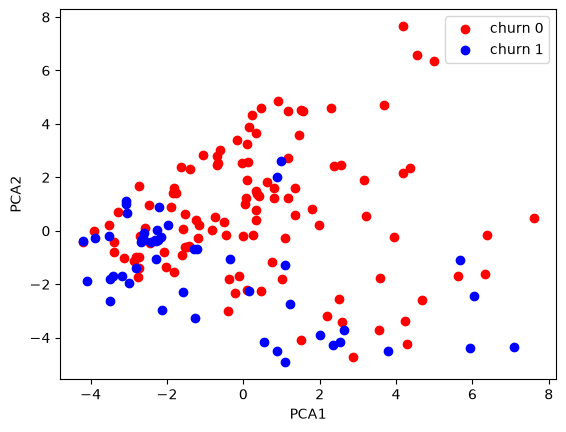

In [78]:
#y_train=0(고객이탈안함)일때 pc1, pc2값 
X1,X2=X_train_pca[y_train==0,0], X_train_pca[y_train==0,1]
plt.scatter(X1,X2, color='r', label="churn 0")

#y_train=1(고객이탈함)일때 pc1 -x축, pc2값-y축 
X1,X2=X_train_pca[y_train==1,0], X_train_pca[y_train==1,1]
plt.scatter(X1,X2, color='b', label="churn 1")

#첫번째 특징- pc1(데이터 정보를 가장 많이 담고있다)
#두번째 특징- pc2(그 안에서 놓친 정보를 보완한다)
plt.xlabel('PCA1')
plt.ylabel('PCA2')
plt.legend()

#주성분의미 : pca1축에서 데이터가 길게 펼쳐져있다.(첫번째 주성분이 이탈고객 여부 특성을 잘 설명함)

In [75]:
#pca로 변환된 학습데이터 중, y_train이 0인 데이터만 선택함
X_train_pca[y_train==0]

array([[-1.88271112,  0.88827871, -0.70044795, ...,  0.74536622,
         0.39532564, -0.80930229],
       [ 0.33925232,  1.50712204,  1.58237982, ..., -1.49510413,
         0.05875169,  1.2276566 ],
       [-3.50671382,  0.23377989, -0.82520459, ..., -0.11315027,
        -0.56331993,  0.21404253],
       ...,
       [ 0.24012978, -0.16562458, -1.8514881 , ..., -0.56509992,
         0.70093084,  0.58794269],
       [-2.43662   , -0.47336174,  0.58546796, ...,  1.65828812,
         0.46077083,  1.36262984],
       [-2.86621342, -1.14027974, -0.3674861 , ...,  1.19885571,
         0.88869946,  0.91122356]], shape=(111, 13))